### Iris Dataset Analysis in Python 
**NAME: KAYODE GIDEON AYOMIDE**

**MATRIC NUMBER: 2025/B/DSC/0198**


1. **DATA IMPORT AND EXPLORATION**

In [25]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [26]:
df = pd.read_csv("iris.csv")

In [27]:
df.head(10)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


In [28]:
df.tail(10)

,sepal_length,sepal_width,petal_length,petal_width,species
140,6.7,3.1,5.6,2.4,virginica
141,6.9,3.1,5.1,2.3,virginica
142,5.8,2.7,5.1,1.9,virginica
143,6.8,3.2,5.9,2.3,virginica
144,6.7,3.3,5.7,2.5,virginica
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


In [29]:
df["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [31]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [32]:
print(f" Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns")

 Dataset shape: 150 rows x 5 columns


In [33]:
print(f"Missing values in the dataset: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")

Missing values in the dataset: 0
Duplicate rows: 1


In [34]:
numeric_features = df.select_dtypes(include="number").columns.tolist()

print(f"Numeric features: {numeric_features}")

Numeric features: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']


2. **DATA VISUALIZATION**

Relationship between different features:


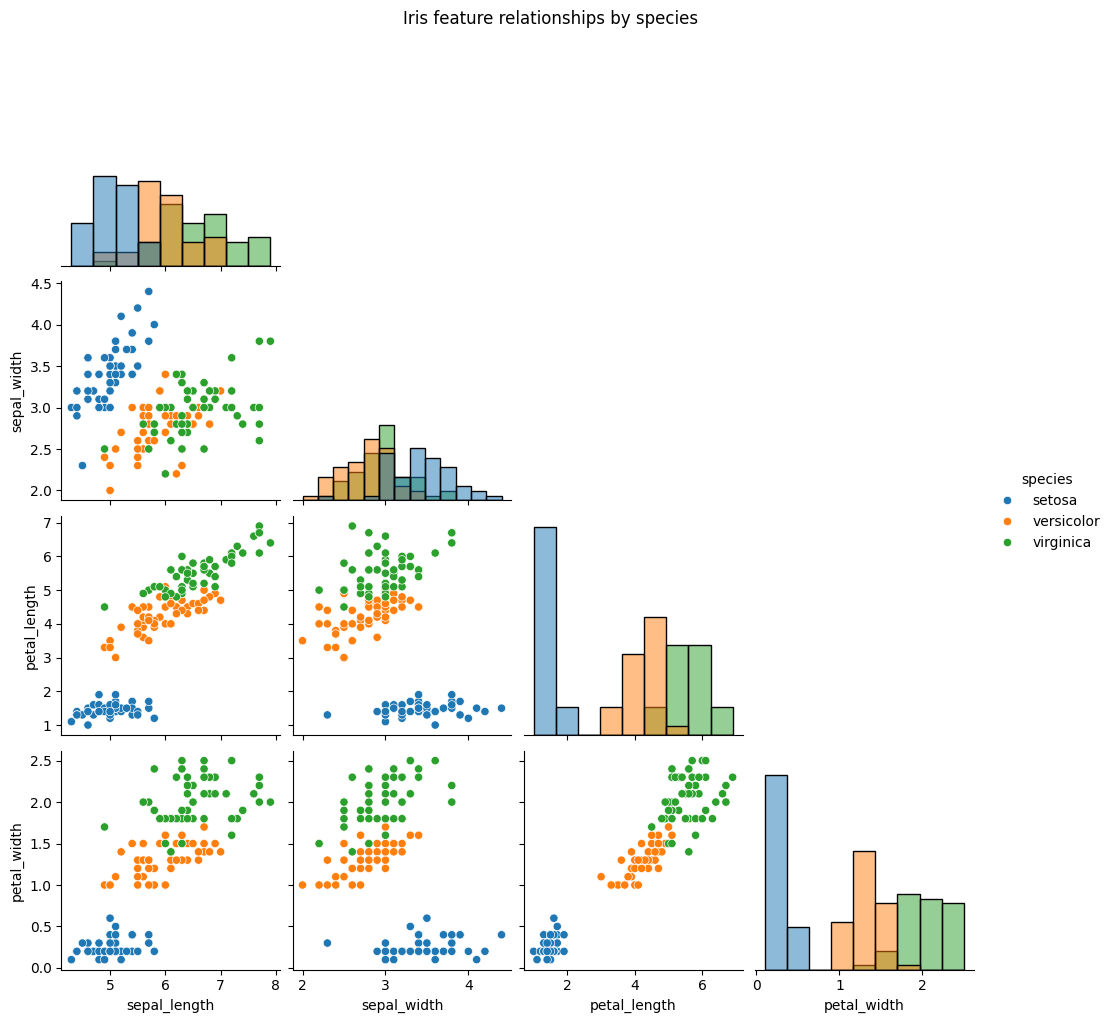

In [35]:
print("Relationship between different features:")
pair_grid = sns.pairplot(df, vars=numeric_features, hue="species", diag_kind="hist", corner=True)
pair_grid.fig.suptitle("Iris feature relationships by species", y=1.02)
plt.show()

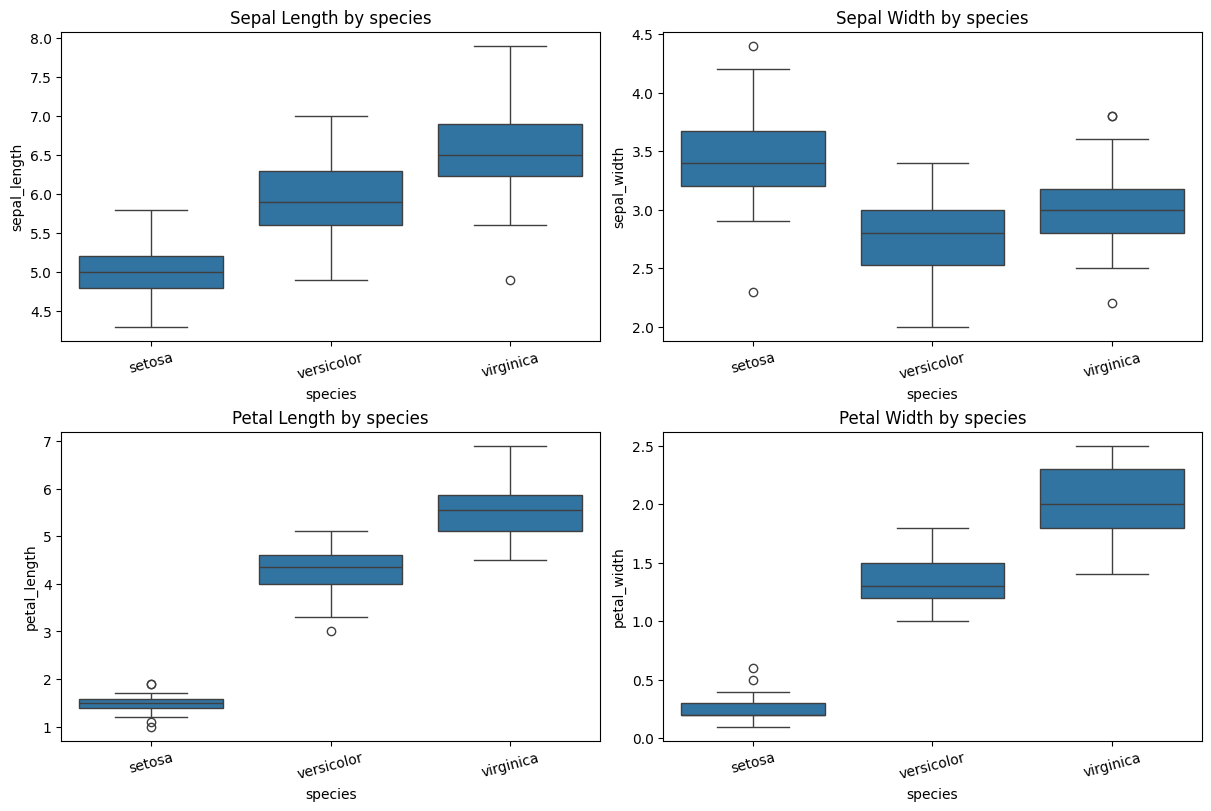

In [36]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, feature in zip(axes.flat, numeric_features):
    sns.boxplot(data=df, x="species", y=feature, ax=ax)
    ax.set_title(f"{feature.replace('_', ' ').title()} by species")
    ax.tick_params(axis="x", rotation=15)
plt.show()

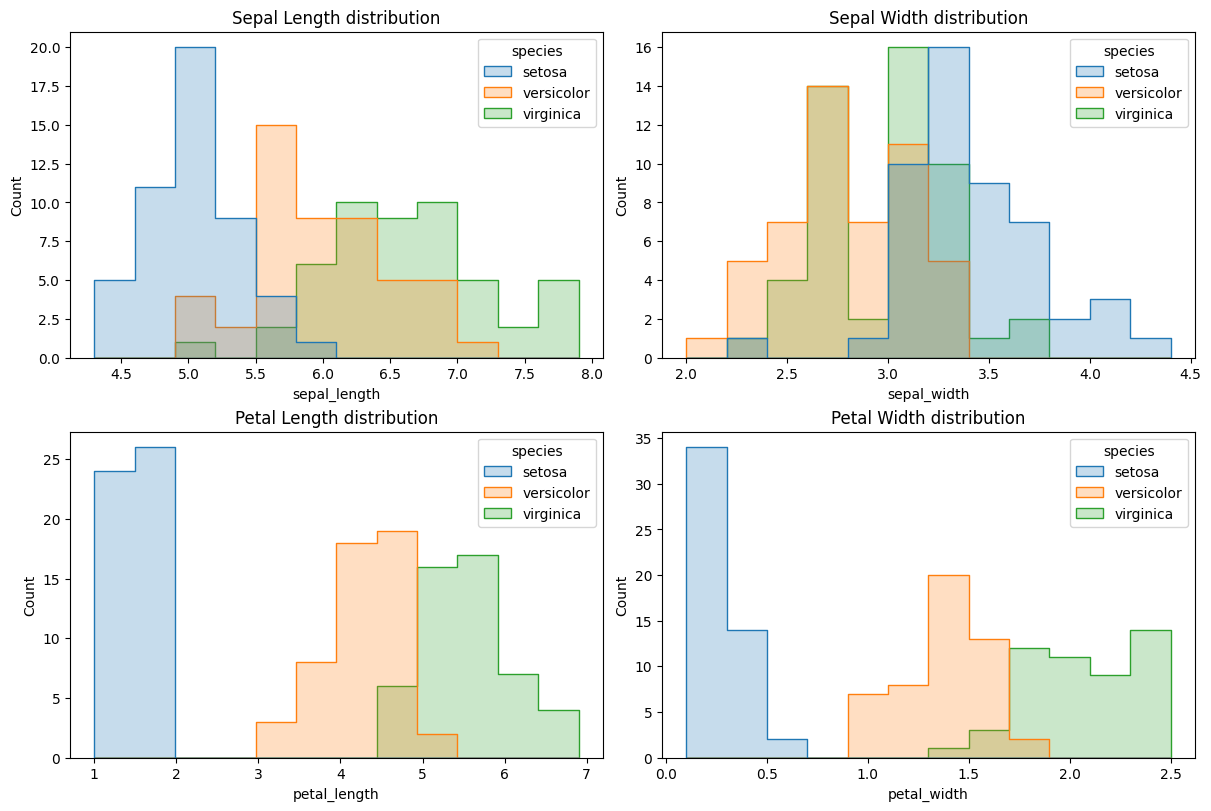

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, feature in zip(axes.flat, numeric_features):
    sns.histplot(data=df, x=feature, hue="species", bins=12, element="step", ax=ax)
    ax.set_title(f"{feature.replace('_', ' ').title()} distribution")
plt.show()

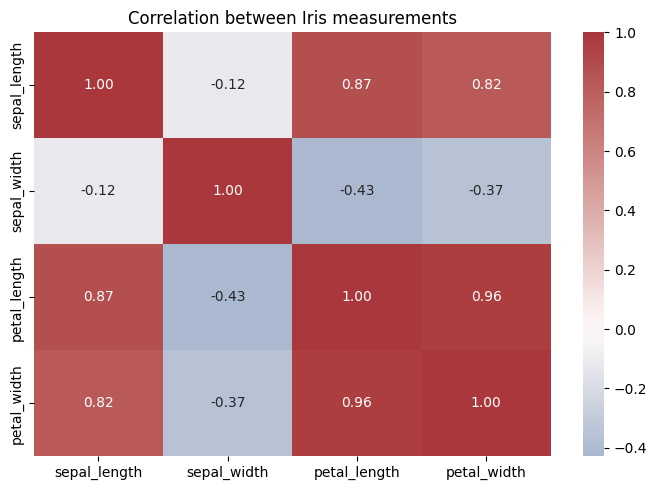

In [38]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[numeric_features].corr(), annot=True, cmap="vlag", center=0, fmt=".2f")
plt.title("Correlation between Iris measurements")
plt.tight_layout()
plt.show()

3. **STATISTICAL SUMMARY**

In [39]:
summary = df[numeric_features].agg(["mean", "median", "std"]).T.round(3)
display(summary)
class_means = df.groupby("species")[numeric_features].mean().round(2)
display(class_means)

,mean,median,std
sepal_length,5.843,5.80,0.828
sepal_width,3.057,3.00,0.436
petal_length,3.758,4.35,1.765
petal_width,1.199,1.30,0.762


,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


4. **CLASSIFICATION MODEL**

In [40]:
X = df[numeric_features]
y = df["species"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)


In [41]:
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)
knn_model.fit(X_train, y_train)
y_pred = knn_model.predict(X_test)
print(f"Training samples: {len(X_train)}; Test samples: {len(X_test)}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")

Training samples: 105; Test samples: 45
Test accuracy: 0.911


In [42]:
print("Classification report:")
print(classification_report(y_test, y_pred, labels=classes, target_names=classes, digits=3, zero_division=0))


Classification report:
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.789     1.000     0.882        15
   virginica      1.000     0.733     0.846        15

    accuracy                          0.911        45
   macro avg      0.930     0.911     0.910        45
weighted avg      0.930     0.911     0.910        45



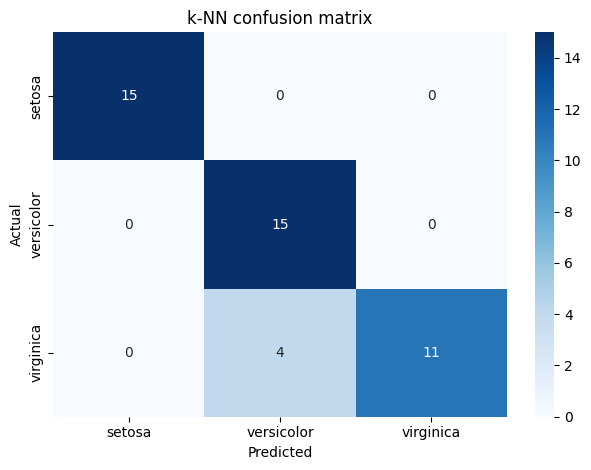

In [43]:
classes = sorted(y.unique())
matrix = confusion_matrix(y_test, y_pred, labels=classes)
confusion = pd.DataFrame(matrix, index=classes, columns=classes)
confusion.index.name = "Actual"
confusion.columns.name = "Predicted"
sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues")
plt.title("k-NN confusion matrix")
plt.tight_layout()
plt.show()